# LSTM Testing
## Loading Data

In [1]:
import pandas as pd

df = pd.read_csv("AirQualityUCI.csv", delimiter=";").dropna(subset=['CO(GT)'])
print(f"ID\tCO Concentration")
print(df['CO(GT)'])

ID	CO Concentration
0       2,6
1         2
2       2,2
3       2,2
4       1,6
       ... 
9352    3,1
9353    2,4
9354    2,4
9355    2,1
9356    2,2
Name: CO(GT), Length: 9357, dtype: str


We can see that some elements seem to be NaN. When preprocessing this, we should remove entries that have NaN values

## Plotting Data

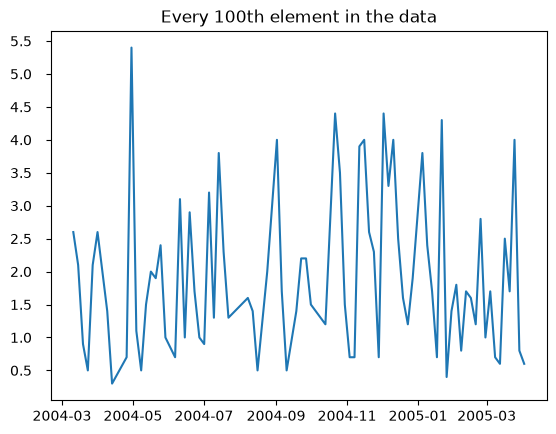

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Formatting and merging data to properly use date values as x axis
df['Datetime'] = df['Date'] + ' ' + df['Time'].replace(regex=r"\.",value=":")
df['CO(GT)'] = df['CO(GT)'].replace(regex=',',value='.').astype(float)

# Also, when sorting the data, it looks like we have some outliers or some issue with the data, as we have random points in the
# CO(GT) data that are negative. We probably don't want that so let's get rid of them
df = df[(df['CO(GT)'] > 0)]

# Plotting all points is too cluttery, so we remove some (this does not affect our dataset):
new_df = df[(df.index % 100 == 0)]
dates = pd.to_datetime(new_df['Datetime'],format='%d/%m/%Y %H:%M:%S')

x = dates.to_numpy()
y = new_df['CO(GT)']

fig, ax = plt.subplots()

ax.yaxis.set_major_locator(plt.MultipleLocator(0.5))

plt.plot(x,y)
plt.title("Every 100th element in the data")
plt.tick_params(axis='y',pad=10)

plt.show()

Interestingly, we notice that the data is trending upwards. When training our model, we will expect this trend to continue.

We would now like to preprocess the data a bit more so that it can be used to train data:
- Normalize the data
- Create two windows: 24 steps in the past and 1 in the future (prediction)

In [ ]:
series = df['CO(GT)'].values
normalized_series = (series - np.min(series)) / (np.max(series) - np.min(series))
print(np.sort(normalized_series))



[0.         0.         0.         ... 0.8559322  0.96610169 1.        ]
